# Volume

Volume bias between 64mT and 3T lowres on the old dataset, per tool, sequence and region:

bias (%) = (64mT − 3T lowres) / 3T lowres × 100

- Same 17 regions as Chapter 05: left/right summed, inferior lateral ventricle counted as
  lateral ventricle, WMH counted as WM (WMH-SynthSeg labels lesions separately; SynthSeg does not).
- Subjects with several 64mT scans: bias per scan, then averaged per subject (n = 11).
- No ICV normalisation. Zero volumes are kept (segmentation failure gives −100%).
- About a third of the 64mT scans are cut off at the bottom of the field of view (Chapter 05,
  *Scans cut off at the bottom*), so their cerebellum and brainstem volumes may be too small.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from common import OLD_OUT

SEG = OLD_OUT / 'seg'
OUT = OLD_OUT / 'volume'
OUT.mkdir(parents=True, exist_ok=True)
MODS = ['T2w', 'T1w', 'FLAIR']

## Regions

SynthSeg reads `volumes_wide.csv`, WMH-SynthSeg reads `volumes_main.csv` (both from Chapter 03).
The two tools name their columns differently; the table below maps both onto the same regions,
ordered from large to small.

In [2]:
FILES = {'SynthSeg':     SEG / 'SynthSeg' / 'volumes_wide.csv',
         'WMH_SynthSeg': SEG / 'WMH_SynthSeg' / 'volumes_main.csv'}
TOOLS = list(FILES)


def lr(name):
    return [f'left {name}', f'right {name}']


# region -> (SynthSeg columns, WMH-SynthSeg columns); columns are summed
REGIONS = {
    'WM':                (lr('cerebral white matter'),   ['left-white-matter(2)', 'right-white-matter(41)', 'WMH(77)']),
    'Cortex':            (lr('cerebral cortex'),         ['left-cortex(3)', 'right-cortex(42)']),
    'Cerebellum-Cortex': (lr('cerebellum cortex'),       ['left-cerebellum-cortex(8)', 'right-cerebellum-cortex(47)']),
    'Cerebellum-WM':     (lr('cerebellum white matter'), ['left-cerebellum-white-matter(7)', 'right-cerebellum-white-matter(46)']),
    'Brainstem':         (['brain-stem'],                ['brainstem(16)']),
    'Lateral-Ventricle': (lr('lateral ventricle') + lr('inferior lateral ventricle'),
                          ['left-lateral-ventricle(4)', 'right-lateral-ventricle(43)']),
    'CSF':               (['csf'],                       ['extracerebral_CSF(24)']),
    'Thalamus':          (lr('thalamus'),                ['left-thalamus(10)', 'right-thalamus(49)']),
    'Putamen':           (lr('putamen'),                 ['left-putamen(12)', 'right-putamen(51)']),
    'Hippocampus':       (lr('hippocampus'),             ['left-hippocampus(17)', 'right-hippocampus(53)']),
    'Caudate':           (lr('caudate'),                 ['left-caudate(11)', 'right-caudate(50)']),
    'VentralDC':         (lr('ventral DC'),              ['left-ventral-DC(28)', 'right-ventral-DC(60)']),
    'Pallidum':          (lr('pallidum'),                ['left-pallidum(13)', 'right-pallidum(52)']),
    'Amygdala':          (lr('amygdala'),                ['left-amygdala(18)', 'right-amygdala(54)']),
    '3rd-Ventricle':     (['3rd ventricle'],             ['3rd-ventricle(14)']),
    '4th-Ventricle':     (['4th ventricle'],             ['4th-ventricle(15)']),
    'Accumbens':         (lr('accumbens area'),          ['left-accumbens(26)', 'right-accumbens(58)']),
}

## Bias per subject

In [3]:
def load(tool):
    """Volume table -> subject, field strength, acq, modality + one column per region (mm³)."""
    df = pd.read_csv(FILES[tool], keep_default_na=False)
    df = df.rename(columns={'sub': 'subject', 'fs': 'field_strength', 'mod': 'modality'})
    i = TOOLS.index(tool)
    vol = pd.DataFrame({r: df[cols[i]].astype(float).sum(axis=1) for r, cols in REGIONS.items()})
    return pd.concat([df[['subject', 'field_strength', 'acq', 'modality']], vol], axis=1)


def bias(vol):
    """Per subject x sequence: bias (%) of each 64mT scan against 3T lowres, averaged over scans."""
    key = ['subject', 'modality']
    ref = vol[vol.acq == 'lowres'].set_index(key)[list(REGIONS)]
    lf = vol[vol.field_strength == '64mT'].set_index(key)[list(REGIONS)]
    ref = ref.reindex(lf.index)
    return ((lf - ref) / ref * 100).groupby(level=key).mean()


vols = {t: load(t) for t in TOOLS}
long = (pd.concat({t: bias(v) for t, v in vols.items()}, names=['tool'])
        .reset_index().melt(id_vars=['tool', 'subject', 'modality'], var_name='region', value_name='pct_diff'))
long.to_csv(OUT / 'bias_long.csv', index=False)

## Volume bias result

Two tables, one per tool: 64mT compared with 3T lowres.

**Input of volume bias: 2 tools**

In [4]:
pd.DataFrame([
    dict(tool=t, file=FILES[t].name, scans_3T_lowres=(v.acq == 'lowres').sum(),
         scans_64mT=(v.field_strength == '64mT').sum(), subjects=v.subject.nunique())
    for t, v in vols.items()
]).set_index('tool')

,file,scans_3T_lowres,scans_64mT,subjects
tool,,,,
SynthSeg,volumes_wide.csv,33,61,11
WMH_SynthSeg,volumes_main.csv,33,61,11


In [5]:
def bias_table(tool):
    """Median [Q1, Q3] of volume bias (%) per region and sequence, 11 subjects."""
    q = long[long.tool == tool].groupby(['region', 'modality']).pct_diff.quantile([0.25, 0.5, 0.75]).unstack()
    cell = q.apply(lambda r: f'{r[0.5]:+.0f} [{r[0.25]:+.0f}, {r[0.75]:+.0f}]', axis=1)
    return cell.unstack('modality').loc[list(REGIONS), MODS]


def plot_bias(tool):
    """Box plot per region (one value per subject): line = median, box = Q1-Q3, dots = outliers."""
    d = long[long.tool == tool]
    fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
    for ax, mod in zip(axes, MODS):
        x = d[d.modality == mod]
        ax.boxplot([x[x.region == r].pct_diff.dropna() for r in REGIONS], widths=0.6, patch_artist=True,
                   boxprops=dict(facecolor='lightgray'), medianprops=dict(color='k'),
                   flierprops=dict(markersize=3))
        ax.axhline(0, color='0.5', lw=0.8)
        ax.set(title=f'{tool} {mod}: 64mT vs 3T lowres', ylabel='Volume bias (%)', ylim=(-105, 105))
        ax.grid(axis='y', alpha=0.3)
    axes[-1].set_xticks(range(1, len(REGIONS) + 1), list(REGIONS), rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

### SynthSeg

Median [Q1, Q3] of volume bias (%), 11 subjects.

In [6]:
bias_table('SynthSeg')

modality,T2w,T1w,FLAIR
region,,,
WM,"+1 [-0, +1]","+1 [-1, +1]","-7 [-8, -6]"
Cortex,"-2 [-3, -2]","+2 [-1, +3]","+5 [+4, +9]"
Cerebellum-Cortex,"-8 [-10, -4]","+2 [-8, +5]","-22 [-34, -6]"
Cerebellum-WM,"-1 [-8, +1]","-7 [-26, +2]","-23 [-38, -4]"
Brainstem,"+2 [-1, +6]","-36 [-62, -12]","-66 [-85, -60]"
Lateral-Ventricle,"+3 [+1, +14]","+12 [+8, +17]","+15 [+10, +29]"
CSF,"+15 [+13, +17]","+13 [+11, +16]","+9 [+4, +16]"
Thalamus,"-3 [-5, +0]","-10 [-17, +0]","-36 [-56, -24]"
Putamen,"-5 [-8, -2]","-20 [-26, -9]","-19 [-23, -17]"


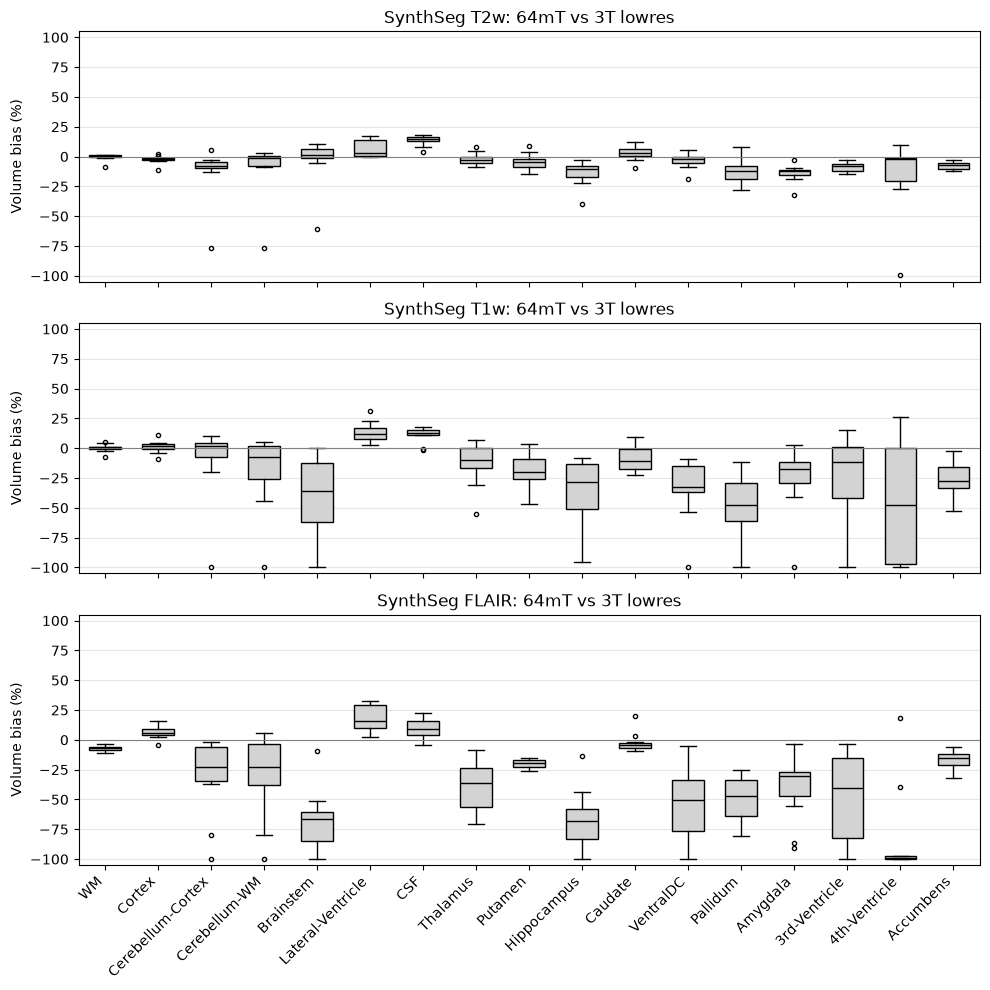

In [7]:
plot_bias('SynthSeg')

### WMH-SynthSeg

Median [Q1, Q3] of volume bias (%), 11 subjects.

In [8]:
bias_table('WMH_SynthSeg')

modality,T2w,T1w,FLAIR
region,,,
WM,"+1 [-0, +2]","-3 [-4, -2]","-7 [-8, -6]"
Cortex,"+2 [+1, +2]","+6 [+4, +7]","+2 [+1, +5]"
Cerebellum-Cortex,"-3 [-8, -2]","+5 [-2, +7]","-3 [-10, +1]"
Cerebellum-WM,"+2 [-6, +4]","-1 [-9, +4]","+6 [-2, +14]"
Brainstem,"-0 [-2, +4]","+2 [-3, +3]","-8 [-13, -0]"
Lateral-Ventricle,"+2 [+1, +6]","+7 [+5, +10]","+11 [+5, +15]"
CSF,"+6 [+1, +7]","+12 [+8, +16]","+10 [+1, +14]"
Thalamus,"+3 [+1, +5]","+13 [+11, +14]","+4 [-2, +5]"
Putamen,"-2 [-9, +1]","+1 [-4, +9]","+2 [-0, +8]"


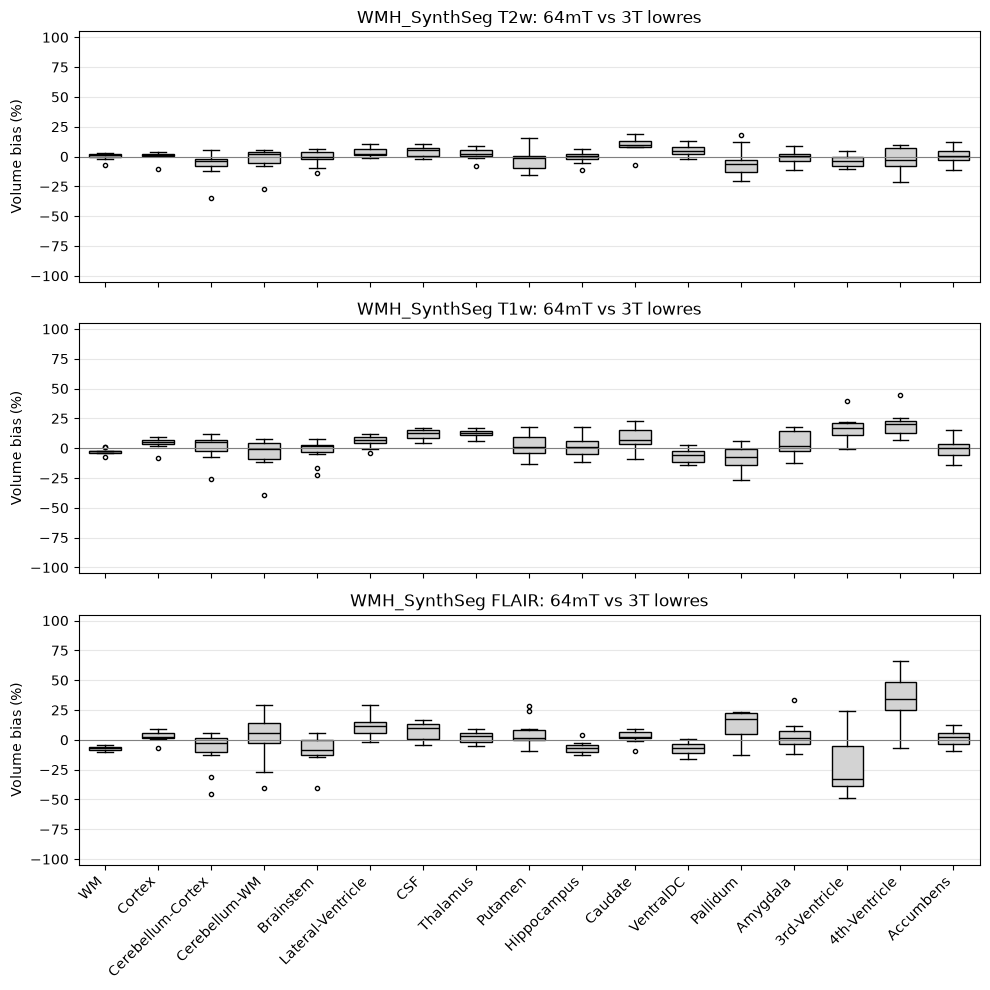

In [9]:
plot_bias('WMH_SynthSeg')

## Conclusion

- **SynthSeg** systematically underestimates deep and lower-brain structures on 64mT scans:
  worst on FLAIR and T1w, still visible on T2w, with segmentation failures (zero volume, −100%).
  SynthSeg is therefore not considered further.
- Volume bias alone cannot tell which regions are reliable enough to serve as a benchmark:
  a small volume bias does not mean the region is segmented in the same place.
  Chapter 07 combines the WMH-SynthSeg volume bias with the Dice of Chapter 05 to answer this.